<div dir="rtl">

# FlyCheck: מחברת EDA (אבן דרך 2)

**השאלה:** האם יש בנתונים סיגנל לחיזוי עיכוב של 30 דקות ומעלה בהמראה מנתב"ג?
**ה-y:** `delayed_30` = 1 אם `delay_minutes ≥ 30`, כאשר `delay_minutes` = זמן המראה בפועל פחות הזמן המתוכנן.

### התובנה
>**גילינו שהעיכובים מצטברים לאורך היום.** לפני 12:00 45% מההמראות יצאו באיחור של 30 דקות ומעלה (n=449), ואחרי 18:00 63% (n=142). הדפוס נשאר גם בתוך אל על לבד: 32% בבוקר מול 64% בערב. לכן הוא לא נובע רק מכך שבערב טסות חברות אחרות. **למשתמש:** אם עיכוב חשוב לך, טיסת בוקר היא בדרך כלל בחירה בטוחה יותר.
>
> ממצא משני: חברת התעופה היא העמודה עם הקשר החזק ביותר ל-y. בין החברות עם 20 טיסות ומעלה, שיעור העיכוב נע בין 7% ל-81%.

### ה-baseline: המספר ש-M3 צריך לנצח
| baseline | איך חושב | Accuracy |
|---|---|---|
| הקטגוריה הנפוצה ("תמיד מתעכבת"), על כל 889 ההמראות | 52.1% מתעכבות | **52.1%** |
| הקטגוריה הנפוצה, בחלוקה כרונולוגית (אימון עד 2.7, בדיקה מ-3.7) | באימון הרוב "מתעכבת", אבל בבדיקה רק 41.9% מתעכבות | **41.9%** |
| שיעור העיכוב של החברה, מימי האימון (מ-`models/metrics.json`) | הסתברות לכל חברה | **58.4%** (ROC-AUC 0.64) |

המודל ב-M3 נבדק בחלוקה הכרונולוגית. לכן המספר שהוא צריך לנצח הוא **41.9%** (הקטגוריה הנפוצה), והיעד האמיתי הוא **58.4% / AUC 0.64** (שיעור החברה).

**הרצה:** מתיקיית הפרויקט, `jupyter notebook notebooks/eda.ipynb`, ואז Restart & Run All. המחברת קוראת רק את `data/processed/`. המסקנות שמורות גם ב-`docs/eda_findings.md`.

</div>

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

%matplotlib inline
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
flights = pd.read_parquet(ROOT / "data/processed/flights.parquet")
report = json.loads((ROOT / "data/processed/cleaning_report.json").read_text("utf-8"))
metrics = json.loads((ROOT / "models/metrics.json").read_text("utf-8"))

# The modelling table: completed international departures with a trusted delay
df = flights[flights["in_model_scope"]].copy()
df["delayed_30"] = df["delayed_30"].astype(int)
print(f"All cleaned flights: {len(flights):,} rows x {flights.shape[1]} columns")
print(f"Modelling table (labelled departures): {len(df):,} rows")

All cleaned flights: 5,213 rows x 25 columns
Modelling table (labelled departures): 889 rows


<div dir="rtl">

## 0. מאיפה הנתונים ומה ניקינו

</div>

<div dir="rtl">

**המקורות:**
- **הארכיון של התמנון** ([odata.org.il](https://www.odata.org.il/he/dataset/flydata), רישיון CC BY): צילומים חוזרים של לוח הטיסות של רשות שדות התעופה.
- **צילום אחד של הלוח החי** מ-data.gov.il, מ-18.11.2026.

בכל צילום של הלוח כל טיסה מופיעה שוב, ולכן השורות הגולמיות הן צילומים ולא טיסות. הטבלה הבאה מראה את משפך הניקוי, כפי שנשמר ב-`cleaning_report.json`.

</div>

Malformed CSV lines skipped: 3
Departures cancelled: 27, without final status: 1637
Completed but excluded: domestic 41, suspect early 1


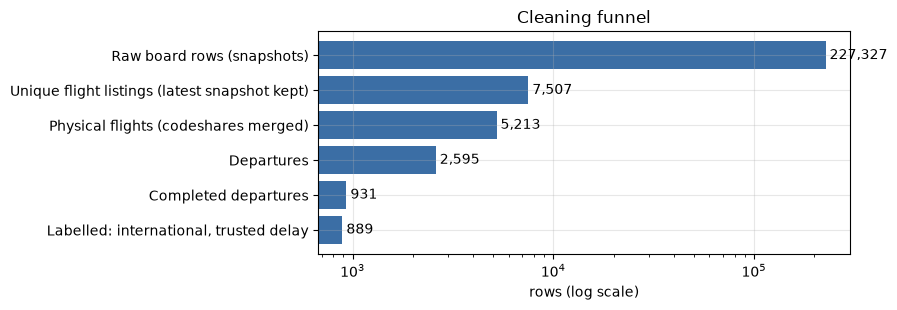

In [2]:
funnel = pd.DataFrame([
    ("Raw board rows (snapshots)", report["raw_rows"]),
    ("Unique flight listings (latest snapshot kept)", report["unique_flight_listings"]),
    ("Physical flights (codeshares merged)", report["physical_flights"]),
    ("Departures", report["departures"]),
    ("Completed departures", report["departures_completed"]),
    ("Labelled: international, trusted delay", report["model_scope_departures"]),
], columns=["step", "rows"])
print(f"Malformed CSV lines skipped: {report['malformed_lines_skipped']}")
print(f"Departures cancelled: {report['departures_cancelled']}, without final status: {report['departures_unresolved']}")
print(f"Completed but excluded: domestic {report['completed_domestic_excluded']}, "
      f"suspect early {report['completed_suspect_early_excluded']}")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(funnel["step"][::-1], funnel["rows"][::-1], color="#3b6ea5")
ax.set_xscale("log")
for i, v in enumerate(funnel["rows"][::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlabel("rows (log scale)")
ax.set_title("Cleaning funnel")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:** מתוך 227,327 שורות גולמיות נשארו **889 המראות מתויגות**. הירידה הגדולה נובעת מכך שכל טיסה נרשמה בעשרות צילומים, ולא מכך שזרקנו מידע.
- **codeshares:** 7,507 רישומים של טיסות התאחדו ל-5,213 טיסות פיזיות. בלי האיחוד, טיסה אחת עם 3 מספרי טיסה הייתה נספרת 3 פעמים.
- **בלי סטטוס סופי:** 1,637 המראות עוד לא הגיעו לסטטוס סופי כשהארכיון נעצר, ולכן אין להן y. הן לא נמחקו. הן נשארות בקובץ ומשמשות לספירת עומס, אבל לא לאימון.
- **ביטולים:** 27 ביטולים מדווחים בנפרד ולא נכנסים לעמודת התשובה.

אחרי הניקוי נשארו 889 שורות, הרבה מעל 300 השורות הנדרשות.

</div>

<div dir="rtl">

## 1. סוגי העמודות

</div>

In [3]:
col_types = {
    "airline_code": ("categorical", "feature"), "airline_name": ("categorical", "label for airline_code"),
    "flight_number": ("identifier", "not a feature (373 values)"), "direction": ("categorical", "constant here (D)"),
    "airport_code": ("categorical", "feature (destination)"), "city": ("categorical", "duplicate of airport_code"),
    "country": ("categorical", "feature"), "terminal": ("categorical (written as number)", "candidate feature"),
    "checkin_counters": ("categorical", "excluded: known only close to departure"),
    "checkin_zone": ("categorical", "excluded: known only close to departure"),
    "status": ("categorical", "LEAKAGE: final status"), "outcome": ("categorical", "LEAKAGE: final status"),
    "scheduled": ("datetime", "source of hour / weekday"), "updated": ("datetime", "LEAKAGE: actual time"),
    "snapshot_time": ("datetime", "technical"), "source": ("categorical", "technical (which archive)"),
    "codeshares": ("text list", "documentation"), "delay_minutes": ("numeric", "LEAKAGE: y is computed from it"),
    "delayed_30": ("binary", "TARGET (y)"), "service_date": ("date", "grouping only"),
    "hour": ("categorical (written as number)", "feature"), "weekday": ("categorical", "feature"),
    "is_domestic": ("binary", "cleaning flag"), "suspect_early": ("binary", "cleaning flag"),
    "in_model_scope": ("binary", "cleaning flag"),
}
types = pd.DataFrame({
    "pandas dtype": df.dtypes.astype(str),
    "unique values": df.nunique(),
    "example": df.iloc[0].astype(str).str.slice(0, 25),
    "type": pd.Series({c: t for c, (t, _) in col_types.items()}),
    "role": pd.Series({c: r for c, (_, r) in col_types.items()}),
})
types

,pandas dtype,unique values,example,type,role
airline_code,str,50,AZ,categorical,feature
airline_name,str,50,ITALIA TRASPORTO AEREO,categorical,label for airline_code
airport_code,str,90,FCO,categorical,feature (destination)
checkin_counters,str,194,7-11,categorical,excluded: known only close to departure
checkin_zone,str,5,A,categorical,excluded: known only close to departure
city,str,88,ROME,categorical,duplicate of airport_code
codeshares,str,448,"AZ 807, LH 5233",text list,documentation
country,str,37,ITALY,categorical,feature
delay_minutes,float64,170,56.0,numeric,LEAKAGE: y is computed from it
delayed_30,int64,2,1,binary,TARGET (y)


<div dir="rtl">

**מסקנה:**
- **שעה, יום בשבוע וטרמינל הם קטגוריות, גם כשהם כתובים כמספרים.** שעה 23 לא "גדולה פי 23" משעה 1, וטרמינל 3 לא "פי 3" מטרמינל 1. לכן במודל הן יקודדו כקטגוריות.
- **`flight_number` הוא מזהה.** יש לו 373 ערכים שונים, כמעט ערך לכל טיסה, ולכן הוא לא פיצ'ר.
- **ארבע עמודות מכילות את התשובה:** `updated` (הזמן בפועל), `delay_minutes`, `status` ו-`outcome`. אסור להכניס אותן למודל. בדיקת הדליפה מופיעה בסעיף 4.
- **דלפקי הצ'ק-אין** ידועים רק סמוך לטיסה, ולא בזמן ההזמנה, ולכן גם הם לא נכנסים.

</div>

<div dir="rtl">

## 2. איכות: חוסרים, כפילויות וערכים חריגים

</div>

                  all cleaned flights (%)  labelled departures (%)
checkin_counters                     57.3                      0.1
checkin_zone                         57.3                      0.1
delay_minutes                        63.6                      0.0
delayed_30                           63.6                      0.0


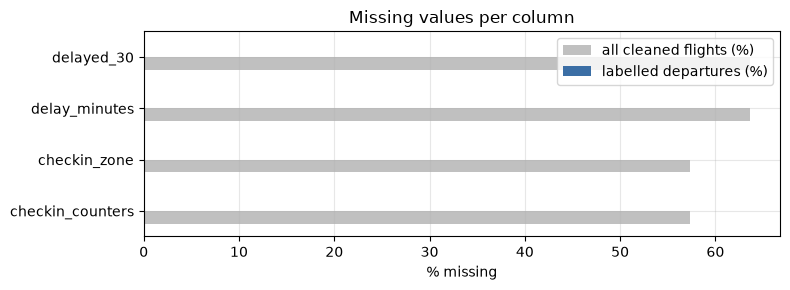

check-in counters missing among arrivals: 100%


In [4]:
missing = pd.DataFrame({
    "all cleaned flights (%)": flights.isna().mean() * 100,
    "labelled departures (%)": df.isna().mean() * 100,
}).round(1)
missing = missing[(missing > 0).any(axis=1)]
print(missing)

ax = missing.plot.barh(figsize=(8, 3), color=["#c0c0c0", "#3b6ea5"])
ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
plt.tight_layout(); plt.show()

arrivals = flights[flights["direction"] == "A"]
print(f"check-in counters missing among arrivals: {arrivals['checkin_counters'].isna().mean():.0%}")

<div dir="rtl">

**מסקנה:** החוסרים אינם רנדומליים. יש להם הסבר מבני, ולכן **לא ממלאים אותם באפס או בממוצע**:
- **דלפקי צ'ק-אין, 57% חסר:** לנחיתות אין צ'ק-אין, וזה כל החוסר. אצל ההמראות המתויגות חסר רק 0.1%. ממילא העמודה לא נכנסת למודל.
- **`delay_minutes` ו-`delayed_30`, 64% חסר:** אלה טיסות שבוטלו או שאין להן סטטוס סופי. אין להן תשובה, ולכן הן לא נכנסות לאימון. הן לא נמחקות, כי הן משמשות לספירת עומס.
- **בטבלת ההמראות המתויגות אין חוסרים בעמודות שנכנסות למודל.**

</div>

In [5]:
key = ["airline_code", "flight_number", "service_date"]
print("Duplicate (airline, flight number, date) in labelled departures:", df.duplicated(key).sum())
print("Snapshots per flight in the raw log ~", round(report["raw_rows"] / report["unique_flight_listings"]), "on average")
print()
print("Example of merged codeshares:")
print(df.loc[df["codeshares"].str.contains(","), ["airline_code", "flight_number", "airport_code", "codeshares"]].head(3).to_string())

Duplicate (airline, flight number, date) in labelled departures: 0
Snapshots per flight in the raw log ~ 30 on average

Example of merged codeshares:
   airline_code flight_number airport_code                 codeshares
1            AZ           807          FCO            AZ 807, LH 5233
10           UX          1302          MAD  UX 1302, MU 4997, AM 6803
16           LH           687          FRA   LH 687, SN 7174, UA 9123


<div dir="rtl">

**מסקנה:**
- **כפילויות מצילומים:** בממוצע כל טיסה הופיעה כ-30 פעמים בלוג הגולמי, אחת לכל צילום. שמרנו רק את הצילום האחרון של כל טיסה, כי הוא מכיל את הסטטוס הסופי.
- **כפילויות מ-codeshare:** כשאותה טיסה פיזית נמכרת תחת כמה מספרי טיסה, אוחדה לשורה אחת. המספרים הנוספים נשמרו בעמודה `codeshares`.
- **אחרי הניקוי אין כפילויות.**

</div>

count    889.0
mean      46.8
std       52.5
min      -21.0
25%       18.0
50%       31.0
75%       55.0
max      386.0
early departures (negative delay): 11  min = -21 min
delays over 3 hours: 30  max = 386 min
excluded before this table as 'left > 30 min early' (likely unrecorded schedule change): 1


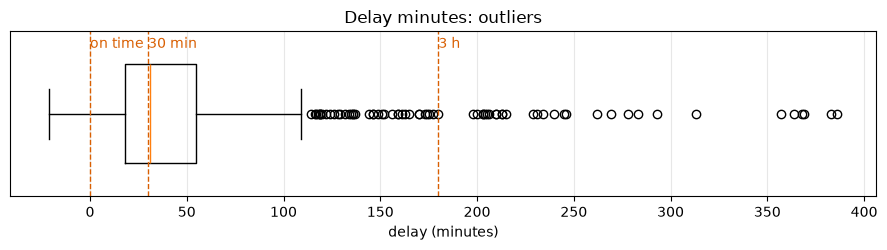

     airline_code flight_number airport_code           scheduled             updated  delay_minutes
36             6H           947          ATH 2026-03-16 23:30:00 2026-03-17 05:56:00          386.0
2520           LY          5479          JMK 2026-07-03 05:45:00 2026-07-03 12:08:00          383.0
2090           A4          3026          KRR 2026-07-02 11:00:00 2026-07-02 17:09:00          369.0
1873           WZ          4312          AER 2026-07-01 20:15:00 2026-07-02 02:23:00          368.0
363            IZ           415          BUS 2026-06-25 04:25:00 2026-06-25 10:29:00          364.0


In [6]:
dm = df["delay_minutes"]
print(dm.describe().round(1).to_string())
print(f"early departures (negative delay): {(dm < 0).sum()}  min = {dm.min():.0f} min")
print(f"delays over 3 hours: {(dm > 180).sum()}  max = {dm.max():.0f} min")
print(f"excluded before this table as 'left > 30 min early' (likely unrecorded schedule change): "
      f"{report['completed_suspect_early_excluded']}")

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.boxplot(dm, orientation="horizontal", widths=0.6)
for x, label in [(0, "on time"), (30, "30 min"), (180, "3 h")]:
    ax.axvline(x, color="#d95f02", ls="--", lw=1); ax.text(x, 1.4, label, color="#d95f02")
ax.set_xlabel("delay (minutes)"); ax.set_yticks([]); ax.set_title("Delay minutes: outliers")
plt.tight_layout(); plt.show()

print(df.nlargest(5, "delay_minutes")[["airline_code", "flight_number", "airport_code", "scheduled", "updated", "delay_minutes"]].to_string())

<div dir="rtl">

**מסקנה:**
- **המראות מוקדמות (11, עד 21 דקות לפני הזמן):** נשארו. המראה מוקדמת של כמה דקות היא דבר אמיתי.
- **"המראה" שקרתה 127 דקות לפני הזמן:** הוצאה. זה כמעט בוודאות שינוי בלוח הזמנים שלא נרשם, ולא טיסה שבאמת יצאה שעתיים מוקדם. הכלל: יציאה מוקדמת ביותר מ-30 דקות מסומנת כחשודה.
- **30 עיכובים של יותר מ-3 שעות (עד 386 דקות):** נשארו. הזמנים שלהם עקביים, למשל טיסה מתוכננת ל-23:30 שיצאה ב-05:56, וזה נראה כמו שיבוש אמיתי. ה-y בינארי, ולכן ערך חריג גבוה לא מעוות אותו: גם 60 וגם 386 דקות הם פשוט "1".

</div>

<div dir="rtl">

## 3. התפלגויות

</div>

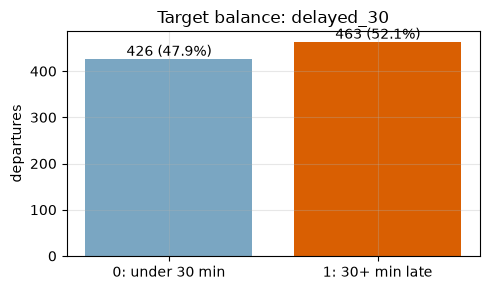

In [7]:
counts = df["delayed_30"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(["0: under 30 min", "1: 30+ min late"], counts.values, color=["#7aa6c2", "#d95f02"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("departures"); ax.set_title("Target balance: delayed_30")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:** **הנתונים מאוזנים.** 52.1% מההמראות התעכבו 30 דקות ומעלה, ו-47.9% לא. יש הרבה דוגמאות משני הסוגים, ולכן לא צריך טיפול מיוחד בחוסר איזון. מצד שני, שיעור כזה גבוה חריג לשדה תעופה, והוא קשור לתקופה שסביב סגירת נתב"ג (11.2–15.5.2026).

</div>

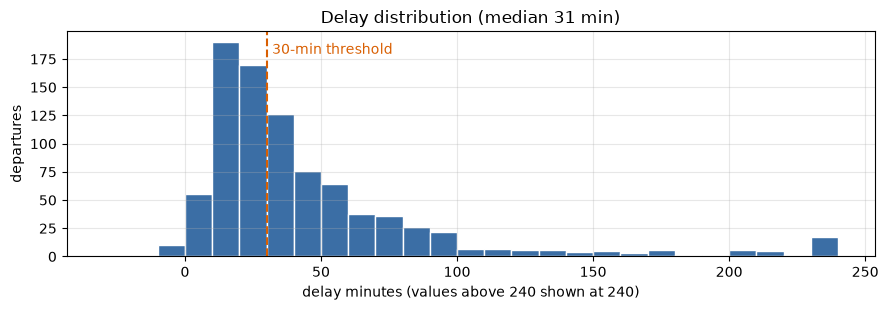

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(df["delay_minutes"].clip(upper=240), bins=np.arange(-30, 250, 10), color="#3b6ea5", edgecolor="white")
ax.axvline(30, color="#d95f02", ls="--"); ax.text(32, ax.get_ylim()[1] * 0.9, "30-min threshold", color="#d95f02")
ax.set_xlabel("delay minutes (values above 240 shown at 240)"); ax.set_ylabel("departures")
ax.set_title(f"Delay distribution (median {df['delay_minutes'].median():.0f} min)")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:**
- **חציון העיכוב הוא 31 דקות,** בדיוק על הסף. לכן שינוי קטן בהגדרה, למשל סף של 15 דקות במקום 30, היה משנה מאוד את האיזון.
- **ההתפלגות מוטה ימינה:** רוב ההמראות מתעכבות 0–60 דקות, ויש זנב ארוך של עיכובים כבדים.
- **מעט מאוד המראות יוצאות מוקדם.**

</div>

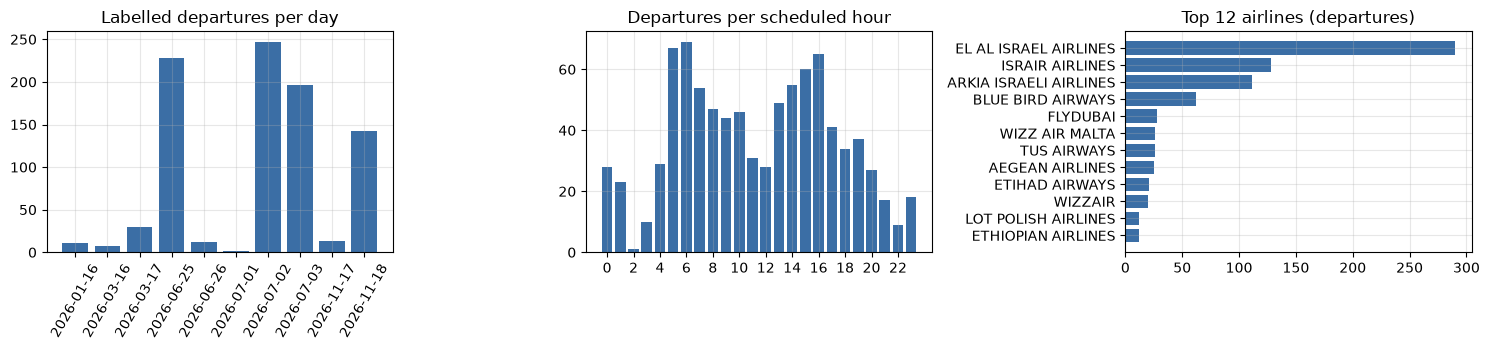

airlines: 50, with 20+ departures: 10
destination airports: 90, with fewer than 5 departures: 46


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
per_day = df["service_date"].astype(str).value_counts().sort_index()
axes[0].bar(per_day.index, per_day.values, color="#3b6ea5"); axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Labelled departures per day")
per_hour = df["hour"].value_counts().sort_index()
axes[1].bar(per_hour.index, per_hour.values, color="#3b6ea5"); axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title("Departures per scheduled hour")
top = df["airline_name"].value_counts().head(12)[::-1]
axes[2].barh(top.index, top.values, color="#3b6ea5"); axes[2].set_title("Top 12 airlines (departures)")
plt.tight_layout(); plt.show()
print(f"airlines: {df['airline_code'].nunique()}, with 20+ departures: {(df['airline_code'].value_counts() >= 20).sum()}")
print(f"destination airports: {df['airport_code'].nunique()}, with fewer than 5 departures: {(df['airport_code'].value_counts() < 5).sum()}")

<div dir="rtl">

**מסקנה:**
- **ימים:** הנתונים מגיעים מ-10 ימים בלבד, ו-4 מהם מכילים 91% מההמראות (25.6, 2.7, 3.7 ו-18.11). **זו המגבלה הכי גדולה של הדאטה:** אי אפשר ללמוד ממנו עונתיות או הבדלים בין חודשים.
- **שעות:** כמעט כל שעות היממה מכוסות, כולל לילה.
- **חברות:** אל על היא שליש מהנתונים. ל-10 חברות בלבד מתוך 50 יש 20 טיסות ומעלה, ול-46 מתוך 90 יעדים יש פחות מ-5 טיסות. לכן לגבי רוב החברות והיעדים אין מספיק נתונים כדי לקבוע משהו.

</div>

<div dir="rtl">

## 4. קורלציה: אילו עמודות זזות יחד, ומה הקשר שלהן לתשובה

</div>

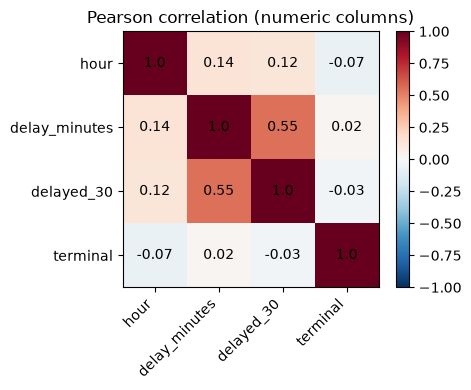

In [10]:
num = df[["hour", "delay_minutes", "delayed_30"]].assign(terminal=pd.to_numeric(df["terminal"]))
corr = num.corr().round(2)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center")
ax.grid(False); fig.colorbar(im); ax.set_title("Pearson correlation (numeric columns)")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:**
- **שעה מול y: 0.12, טרמינל מול y: -0.03.** קשר ליניארי חלש. אבל שעה היא קטגוריה, וקורלציה ליניארית לא מתאימה לה, ולכן בהמשך בודקים אותה לפי שיעור עיכוב לכל שעה.
- **`delay_minutes` מול y: 0.55.** הקורלציה לא מגיעה ל-0.98, כי y בינארי ו-`delay_minutes` רציף. בכל זאת זו **דליפה מלאה**, כי y מחושב ממנה. הבדיקה הבאה מראה את זה.

</div>

In [11]:
print("Leakage check: does delay_minutes >= 30 reproduce y exactly?")
print(pd.crosstab(df["delay_minutes"] >= 30, df["delayed_30"], rownames=["delay_minutes>=30"], colnames=["delayed_30"]))
actual_minus_sched = (df["updated"] - df["scheduled"]).dt.total_seconds() / 60
print("\nupdated - scheduled == delay_minutes for", f"{(actual_minus_sched == df['delay_minutes']).mean():.0%}", "of rows")
print("status values in labelled data:", df["status"].unique())

Leakage check: does delay_minutes >= 30 reproduce y exactly?
delayed_30           0    1
delay_minutes>=30          
False              426    0
True                 0  463

updated - scheduled == delay_minutes for 100% of rows
status values in labelled data: <ArrowStringArray>
['DEPARTED']
Length: 1, dtype: str


<div dir="rtl">

**מסקנה (בדיקת דליפה):**
- **`delay_minutes`:** ממנה אפשר לשחזר את y ב-100% מהשורות, בלי טעות אחת.
- **`updated`:** גם הזמן בפועל מחזיר את y ב-100% ביחד עם הזמן המתוכנן.
- **`status`:** כאן יש רק ערך אחד, DEPARTED. הוא נודע רק אחרי הטיסה.

לכן **שלוש העמודות האלה לא ייכנסו למודל.** המודל משתמש רק במה שידוע בזמן ההזמנה: חברה, יעד, מדינה, שעה, יום בשבוע וטרמינל.

y מחושב מנוסחה על זמנים שנמדדו, כלומר המודל צריך ללמוד את העיכוב עצמו ולא את הנוסחה. זה עובד רק כל עוד עמודות הזמן בפועל לא נכנסות אליו.

</div>

      column  categories  cramers_v p_value
    terminal           2      0.031    0.35
     weekday           5      0.207 1.1e-07
        hour          24      0.255 7.4e-05
     country          37      0.317 2.1e-06
airport_code          90      0.420 1.2e-05
airline_code          50      0.424   1e-13


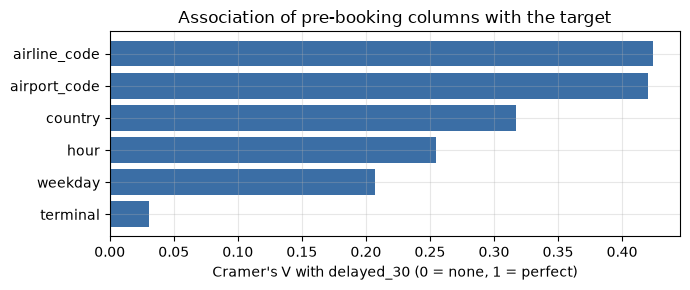

In [12]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p

rows = []
for col in ["airline_code", "airport_code", "country", "hour", "weekday", "terminal"]:
    v, p = cramers_v(df[col], df["delayed_30"])
    rows.append((col, df[col].nunique(), round(v, 3), f"{p:.2g}"))
assoc = pd.DataFrame(rows, columns=["column", "categories", "cramers_v", "p_value"]).sort_values("cramers_v")
print(assoc.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(assoc["column"], assoc["cramers_v"], color="#3b6ea5")
ax.set_xlabel("Cramer's V with delayed_30 (0 = none, 1 = perfect)"); ax.set_title("Association of pre-booking columns with the target")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:** **הקשר החזק ביותר הוא עם חברת התעופה (V≈0.42),** אחריה היעד והמדינה, ואחריהם שעה ויום בשבוע. **לטרמינל אין קשר** (V≈0.03, p≈0.35).

**זהירות:** בעמודה עם הרבה קטגוריות ומעט טיסות בכל אחת, Cramér's V מנופח. ליעד יש 90 קטגוריות, ולחלקן טיסה אחת או שתיים. לכן ה-V הגבוה של היעד אמין פחות מזה של החברה, שמבוסס על קבוצות גדולות יותר.

</div>

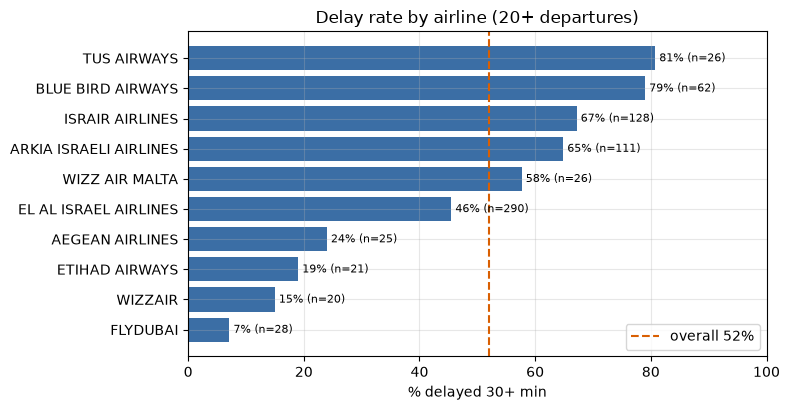

In [13]:
def rate_plot(col, label_col=None, min_n=20, title=""):
    g = df.groupby(col).agg(rate=("delayed_30", "mean"), n=("delayed_30", "size"))
    if label_col:
        g.index = df.groupby(col)[label_col].first().reindex(g.index)
    g = g[g["n"] >= min_n].sort_values("rate")
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(g) + 1))
    ax.barh(g.index.astype(str), g["rate"] * 100, color="#3b6ea5")
    ax.axvline(df["delayed_30"].mean() * 100, color="#d95f02", ls="--", label="overall 52%")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(r * 100, i, f" {r:.0%} (n={n})", va="center", fontsize=8)
    ax.set_xlim(0, 100); ax.set_xlabel("% delayed 30+ min"); ax.set_title(title); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()
    return g

by_airline = rate_plot("airline_code", "airline_name", title="Delay rate by airline (20+ departures)")

<div dir="rtl">

**מסקנה:** הפער בין החברות עצום:
- **flydubai: 7%,** Wizz Air: 15%, Etihad: 19%, Aegean: 24%;
- **אל על: 46%,** והיא שליש מהנתונים;
- **Arkia: 65%, Israir: 67%, Blue Bird: 79%, TUS: 81%.**

גם ב-baseline של שיעור החברה, שנלמד מימי האימון ונבדק על ימים מאוחרים, החברה עדיין מבדילה בין טיסות (AUC 0.64). זה סימן שהסיגנל לא נובע רק מיום אחד.

**הסתייגות:** כל חברה טסה בימים מסוימים, ולכן חלק מהפער עשוי לנבוע מהימים ולא מהחברה עצמה.

</div>

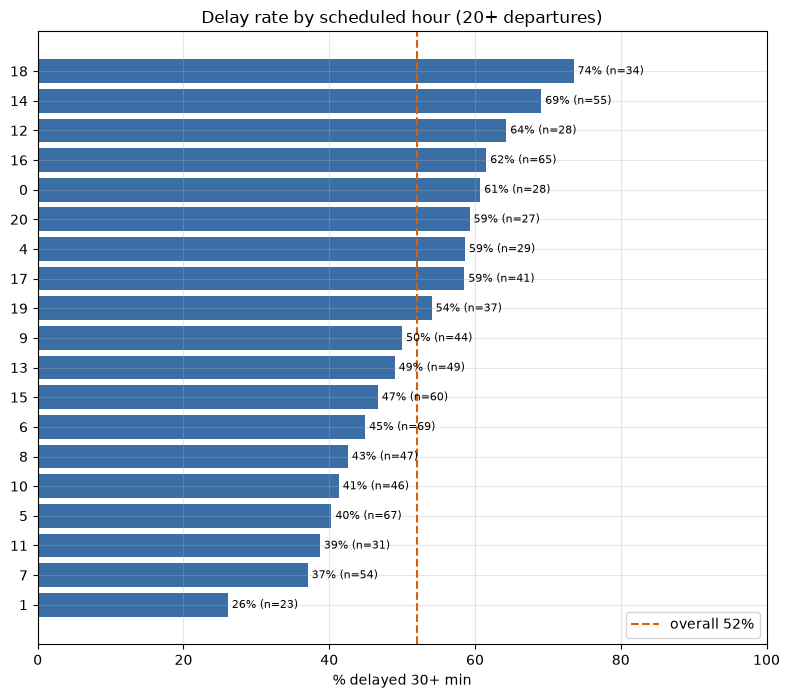

In [14]:
by_hour = rate_plot("hour", title="Delay rate by scheduled hour (20+ departures)")

<div dir="rtl">

**מסקנה:**
- **הכי נמוך:** 01:00 (26%), 07:00 (37%) ו-11:00 (39%).
- **הכי גבוה:** 14:00 (69%) ו-18:00 (74%).

הדפוס מתאים לתופעה מוכרת: עיכובים מצטברים במהלך היום, כי מטוס שהתעכב בבוקר מעכב את הטיסות הבאות שלו. אבל אולי זה רק תמהיל החברות? הבדיקה הבאה בודקת את זה.

</div>

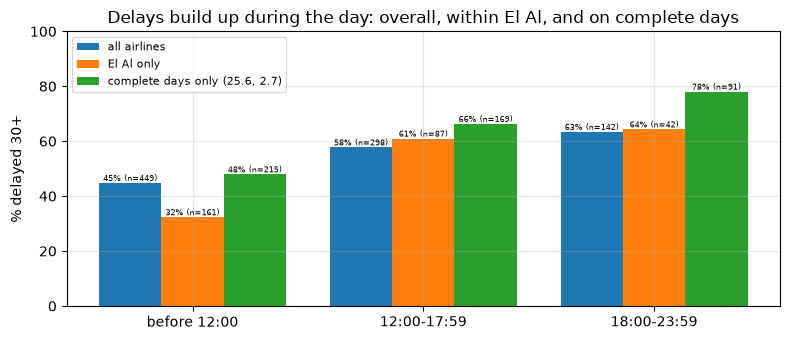

all airlines      El Al only      complete days only (25.6, 2.7)     
                     mean size       mean size                           mean size
hour                                                                              
before 12:00        0.448  449      0.323  161                          0.479  215
12:00-17:59         0.577  298      0.609   87                          0.663  169
18:00-23:59         0.634  142      0.643   42                          0.780   91

In [15]:
period = pd.cut(df["hour"], [-1, 11, 17, 23], labels=["before 12:00", "12:00-17:59", "18:00-23:59"])
full_days = df["service_date"].astype(str).isin(["2026-06-25", "2026-07-02"])
groups = {
    "all airlines": df["airline_code"].notna(),
    "El Al only": df["airline_code"].eq("LY"),
    "complete days only (25.6, 2.7)": full_days,
}
tables = {name: df[mask].groupby(period[mask], observed=True)["delayed_30"].agg(["mean", "size"]) for name, mask in groups.items()}
fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.27
for k, (name, g) in enumerate(tables.items()):
    x = np.arange(len(g)) + (k - 1) * width
    ax.bar(x, g["mean"] * 100, width, label=name)
    for xi, (r, n) in zip(x, zip(g["mean"], g["size"])):
        ax.text(xi, r * 100, f"{r:.0%} (n={n})", ha="center", va="bottom", fontsize=6)
ax.set_xticks(range(3), list(tables["all airlines"].index))
ax.set_ylim(0, 100); ax.set_ylabel("% delayed 30+"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Delays build up during the day: overall, within El Al, and on complete days")
plt.tight_layout(); plt.show()
pd.concat(tables, axis=1).round(3)

<div dir="rtl">

**מסקנה (זו התובנה):** העיכובים מצטברים לאורך היום בשלושת החיתוכים:
- **כל החברות:** 45% לפני 12:00, 58% בצהריים, 63% אחרי 18:00.
- **אל על לבד:** 32%, 61%, 64%. **הדפוס נשאר גם בתוך חברה אחת,** ולכן הוא לא רק תוצאה של תמהיל החברות.
- **רק בשני הימים שנרשמו עד הסוף:** 48%, 66%, 78%. הדפוס אפילו חזק יותר, כי ביום האחרון של כל מקור חלק מטיסות הערב המאוחרות לא קיבלו תיוג (סעיף 4).

ממצא זה הגיע מחבר צוות ב-21.11, ואומת כאן.

</div>

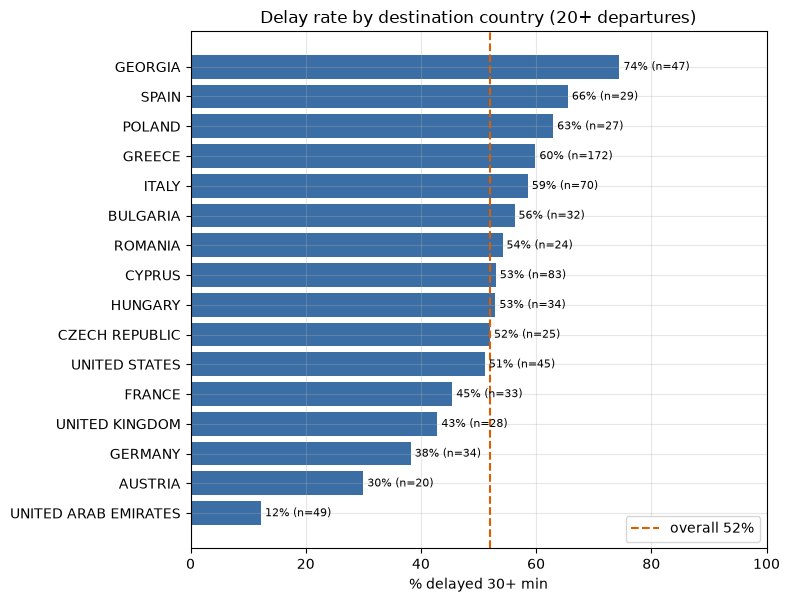

In [16]:
by_country = rate_plot("country", title="Delay rate by destination country (20+ departures)")

<div dir="rtl">

**מסקנה:** איחוד האמירויות הכי נמוך (12%), וגאורגיה הכי גבוהה (74%). הסדר הזה משקף **בעיקר את החברות שטסות לכל מדינה**, למשל flydubai ו-Etihad לאמירויות. לכן מדינה וחברה הן עמודות שזזות יחד, ולא סיגנל נפרד לגמרי. במודל צריך לבדוק אם מדינה מוסיפה משהו מעבר לחברה.

</div>

Which dates does each weekday come from?
weekday       Friday  Monday  Thursday  Tuesday  Wednesday
service_date                                              
2026-01-16        11       0         0        0          0
2026-03-16         0       8         0        0          0
2026-03-17         0       0         0       30          0
2026-06-25         0       0       228        0          0
2026-06-26        12       0         0        0          0
2026-07-01         0       0         0        0          2
2026-07-02         0       0       247        0          0
2026-07-03       196       0         0        0          0
2026-11-17         0       0         0       13          0
2026-11-18         0       0         0        0        142

Delay rate on days with 100+ departures:
              mean  size
service_date            
2026-06-25    0.60   228
2026-07-02    0.61   247
2026-07-03    0.48   196
2026-11-18    0.33   142


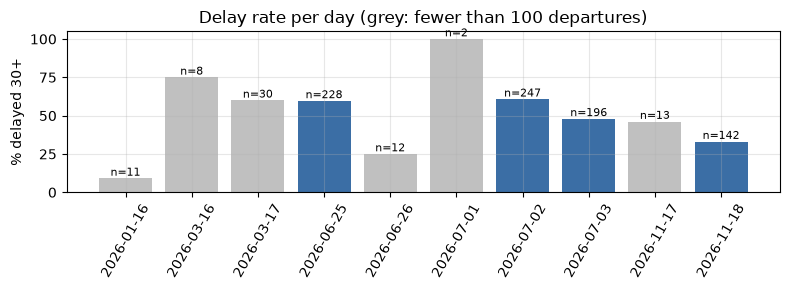

In [17]:
print("Which dates does each weekday come from?")
print(pd.crosstab(df["service_date"].astype(str), df["weekday"]))
daily = df.groupby(df["service_date"].astype(str))["delayed_30"].agg(["mean", "size"])
big = daily[daily["size"] >= 100]
print("\nDelay rate on days with 100+ departures:")
print(big.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(daily.index, daily["mean"] * 100, color=["#3b6ea5" if n >= 100 else "#c0c0c0" for n in daily["size"]])
for i, (r, n) in enumerate(zip(daily["mean"], daily["size"])):
    ax.text(i, r * 100, f"n={n}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("% delayed 30+"); ax.tick_params(axis="x", rotation=60)
ax.set_title("Delay rate per day (grey: fewer than 100 departures)")
plt.tight_layout(); plt.show()

<div dir="rtl">

**מסקנה:**
- **יום בשבוע לא ניתן להפרדה מהתאריך.** כל יום בשבוע מגיע מ-1 עד 3 תאריכים בלבד. למשל, "חמישי" הוא 25.6 ו-2.7. לכן הקשר שנראה בין יום בשבוע לעיכוב (V≈0.21) הוא בעצם **ההבדל בין הימים הספציפיים**.
- **השונות בין הימים גדולה:** בימים שיש בהם 100 המראות ומעלה, שיעור העיכוב נע בין 33% (18.11) ל-61% (2.7).
- **ההשלכה ל-M3:** בחלוקה כרונולוגית, ימי הבדיקה (3.7 ו-17–18.11) פחות מעוכבים מימי האימון (42% מול 59%). זה מקשה על כל מודל ומסביר את ה-baseline הנמוך. חלק מהפער הזה הוא כנראה הטיה ולא מציאות. הבדיקה הבאה מראה את זה.

</div>

In [18]:
# Censoring check (found by a teammate on 21.11): on the last day each source recorded,
# late evening flights may not have departed yet when logging stopped -> no label.
intl_dep = flights[(flights["direction"] == "D") & ~flights["is_domestic"]]
check = (intl_dep.assign(period=np.where(intl_dep["hour"] >= 18, "evening 18-23", "before 18"),
                         day=intl_dep["service_date"].astype(str))
         .query("day in ['2026-06-25', '2026-07-02', '2026-07-03', '2026-11-18']"))
summary = check.groupby(["day", "period"]).agg(
    departures=("outcome", "size"),
    no_final_status=("outcome", lambda s: f"{(s == 'unresolved').mean():.0%}"),
    labelled=("in_model_scope", "sum"),
    delayed_share=("delayed_30", lambda s: f"{s.dropna().astype(int).mean():.0%}" if s.notna().any() else "-"),
)
summary

departures no_final_status  labelled delayed_share
day        period                                                           
2026-06-25 before 18             187              0%       185           55%
           evening 18-23          44              0%        43           79%
2026-07-02 before 18             205              0%       199           56%
           evening 18-23          48              0%        48           77%
2026-07-03 before 18             189              0%       181           50%
           evening 18-23          15              0%        15           20%
2026-11-18 before 18             133              0%       133           35%
           evening 18-23          29             69%         9            0%

<div dir="rtl">

**מסקנה (הטיה ביום האחרון של כל מקור):**
- **25.6 ו-2.7:** ימים שנרשמו עד הסוף. בערב 77%–79% מההמראות התעכבו.
- **18.11:** היום האחרון בצילום של הלוח החי. ל-**69% מטיסות הערב אין סטטוס סופי.** מבין טיסות הערב שכן תויגו, **אף אחת** לא התעכבה (0 מתוך 9).
- **3.7:** היום האחרון בארכיון. נרשמו בו רק 15 טיסות ערב, לעומת 43–48 בימים המלאים, ומהן רק 20% התעכבו.

**ההסבר:** טיסה שהתעכבה עוד לא המריאה כשהרישום נעצר, ולכן אין לה תיוג. לכן ימי הבדיקה מוטים לכיוון "בזמן", וחלק מהירידה ל-42% היא הטיה ולא שינוי אמיתי. את הממצא הזה מצא חבר צוות ב-21.11.

**ל-M3:** כדאי להוציא מהאימון ומהבדיקה את השעות האחרונות של היום האחרון בכל מקור, או לבחור ימי בדיקה שנרשמו עד הסוף.

</div>

<div dir="rtl">

## 5. baseline

</div>

In [19]:
majority_all = df["delayed_30"].mode()[0]
acc_all = (df["delayed_30"] == majority_all).mean()

split = metrics["tasks"]["delay"]["split"]
test_days = set(split["test_days"])
is_test = df["service_date"].astype(str).isin(test_days)
train, test = df[~is_test], df[is_test]
majority_train = train["delayed_30"].mode()[0]
acc_chrono = (test["delayed_30"] == majority_train).mean()

airline_rate = metrics["tasks"]["delay"]["results"]["Airline rate (archive)"]["test"]
baselines = pd.DataFrame([
    ("Majority class, all 889 rows", f"always {majority_all}", round(acc_all, 3), None),
    (f"Majority class, train {len(train)} / test {len(test)} (chronological)", f"always {majority_train}", round(acc_chrono, 3), 0.5),
    ("Airline delay rate from training days (models/metrics.json)", "per-airline probability",
     airline_rate["accuracy"], airline_rate["roc_auc"]),
], columns=["baseline", "prediction", "accuracy", "roc_auc"])
print(f"test days: {sorted(test_days)}; delayed share train {train['delayed_30'].mean():.1%}, test {test['delayed_30'].mean():.1%}")
baselines

test days: ['2026-07-03', '2026-11-17', '2026-11-18']; delayed share train 58.7%, test 41.9%


,baseline,prediction,accuracy,roc_auc
0,"Majority class, all 889 rows",always 1,0.521,NaN
1,"Majority class, train 538 / test 351 (chronolo...",always 1,0.419,0.5000
2,Airline delay rate from training days (models/...,per-airline probability,0.584,0.6403


<div dir="rtl">

**מסקנה:**
- **הקטגוריה הנפוצה, על כל הנתונים:** אם תמיד חוזים "תתעכב", מקבלים **52.1%** דיוק.
- **הקטגוריה הנפוצה, בחלוקה הכרונולוגית שבה ייבדק המודל:** מאמנים על הימים המוקדמים, ובהם הרוב "מתעכבת". אבל בימי הבדיקה רק 41.9% מתעכבות, ולכן הדיוק יורד ל-**41.9%**. חלק מהירידה נובע מההטיה ביום האחרון של כל מקור, שמתוארת בסעיף 4.
- **שיעור העיכוב של החברה:** **58.4%** דיוק, עם ROC-AUC של 0.64. זה ה-baseline החזק.

**המספר ש-M3 צריך לנצח:** 41.9% הוא הרף המינימלי. היעד האמיתי הוא 58.4% / AUC 0.64, כי מודל שלא עובר את שיעור החברה לא מוסיף ערך למשתמש.

</div>

<div dir="rtl">

## סיכום

1. **הנתונים:** 889 המראות מתויגות, מאוזנות (52% מתעכבות), בלי חוסרים בעמודות שנכנסות למודל ובלי כפילויות.
2. **יש סיגנל.** **התובנה:** העיכובים מצטברים לאורך היום, 45% לפני 12:00 מול 63% אחרי 18:00, וגם בתוך אל על לבד (32% מול 64%). לחברת התעופה יש הקשר החזק ביותר ל-y (7%–81%). המדינה חופפת ברובה לחברה, ולטרמינל אין השפעה.
3. **דליפה:** `delay_minutes`, `updated` ו-`status` מכילות את התשובה, ולא נכנסות למודל.
4. **המגבלה הגדולה:** 10 ימים בלבד, עם שונות גדולה בין הימים. אי אפשר ללמוד מהם יום בשבוע או עונתיות, ומודל עלול ללמוד "ימים" במקום דפוסים.
   - בנוסף, ביום האחרון של כל מקור טיסות ערב שהתעכבו לא קיבלו תיוג, ולכן ימי הבדיקה מוטים לכיוון "בזמן".
5. **ל-M3:**
   - לנצח את ה-baseline: 41.9% כרף מינימלי, ו-58.4% / AUC 0.64 כיעד;
   - פיצ'רים: חברה ושעה, ואולי מדינה;
   - לטפל בהטיה של היום האחרון בכל מקור;
   - דאטה גדול יותר (Rank Air או EUROCONTROL) הוא מה שהכי צפוי לעזור.

</div>